In [3]:
import matplotlib.pyplot as plt
import multiprocessing as mp
##matplotlib.use('Agg')
import pandas as pd
from sklearn.externals import joblib
import scipy
from itertools import combinations
import numpy as np
import ants
from skimage import measure
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
import json
import numpy as np
from numpy.testing import assert_raises
from nilearn import datasets, surface, image
from nilearn.plotting import html_surface, html_connectome
from nilearn.plotting.js_plotting_utils import decode
from nilearn.datasets import fetch_surf_fsaverage
from nilearn._utils.exceptions import DimensionError
from matplotlib import gridspec
from nilearn import surface, plotting, datasets
import seaborn as sns
import os, sys
import glob
import json
import os
import copy
from statsmodels.regression.linear_model import OLS
from sklearn.linear_model import Lasso, logistic, LinearRegression, \
LogisticRegression, RidgeClassifier, RidgeClassifierCV
from sklearn.svm import SVR, SVC
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
import xgboost
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, roc_auc_score, average_precision_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler, LabelBinarizer, RobustScaler
from sklearn.feature_selection import SelectFromModel, f_regression, SelectKBest, SelectPercentile, SelectFwe, \
  f_classif, SelectFdr
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, LeaveOneOut, KFold, RepeatedStratifiedKFold, RepeatedKFold
from scipy import stats
from shutil import copyfile
import numpy as np
import pandas as pd
import nibabel as nb

import xgboost as xgb
from imblearn.over_sampling import ADASYN, SMOTE, RandomOverSampler
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics.scorer import make_scorer
sns.set("paper", font_scale=2)
sns.set_style('ticks', {'font.family':'sans-serif', 'font.serif':'Helvetica'})
%matplotlib inline
%reload_ext rpy2.ipython
%lsmagic

from sklearn.metrics import make_scorer
def specificity_loss_func(ground_truth, predictions):
    tp, tn, fn, fp = 0.0,0.0,0.0,0.0
    tn, fp, fn, tp = confusion_matrix(ground_truth, predictions).ravel()
    return tn/(tn+fp)

def fpr_loss_func(ground_truth, predictions):
    tn, fp, fn, tp = confusion_matrix(ground_truth, predictions).ravel()
    return 1.0*fp/(tn+fp)

spec_score = make_scorer(specificity_loss_func, greater_is_better=True)
#fpr_score = make_scorer(fpr_loss_func, greater_is_better=False)
fpr_score = make_scorer(fpr_loss_func, greater_is_better=True)

/home/qinqian/.local/lib/python3.6/site-packages/sklearn/externals/joblib/__init__.py:15: DeprecationWarning: sklearn.externals.joblib is deprecated in 0.21 and will be removed in 0.23. Please import this functionality directly from joblib, which can be installed with: pip install joblib. If this warning is raised when loading pickled models, you may need to re-serialize those models with scikit-learn 0.21+.
  warnings.warn(msg, category=DeprecationWarning)
Using TensorFlow backend.


Limited tf.compat.v2.summary API due to missing TensorBoard installation
Limited tf.summary API due to missing TensorBoard installation


In [4]:
jhu_df = pd.read_csv('jhu_roi_model_raw_fillna.csv')
peaktsb = pd.read_csv('peak_tsb.txt', sep='\t')
final = jhu_df.merge(peaktsb, left_on='participant_id', right_on='participant_id')

outcomes_continue = ['Cognitive_12m', 'Fine Motor_12m',
       'Gross Motor_12m', 'Receptive Communication_12m',
       'Expressive Communication_12m', 'Cognitive_18m', 'Fine Motor_18m',
       'Gross Motor_18m', 'Receptive Communication_18m',
       'Expressive Communication_18m']

response = final.loc[:, outcomes_continue]
brain_markers = final.loc[:, list(final.columns[1:(122*9+1)])+['BEAP', 'Peak-TSB', 'GA', 'CGA', 'bw', 'sex']]
brain_markers.columns[:-5]

Index(['JAC_corpus callosum_left', 'MD_corpus callosum_left',
       'ALFF_corpus callosum_left', 'fALFF_corpus callosum_left',
       'ReHo_corpus callosum_left', 'FA_corpus callosum_left',
       'OD_corpus callosum_left', 'ICVF_corpus callosum_left',
       'ISOVF_corpus callosum_left', 'JAC_corpus callosum_right',
       ...
       'JAC_insular cortex_right', 'MD_insular cortex_right',
       'ALFF_insular cortex_right', 'fALFF_insular cortex_right',
       'ReHo_insular cortex_right', 'FA_insular cortex_right',
       'OD_insular cortex_right', 'ICVF_insular cortex_right',
       'ISOVF_insular cortex_right', 'BEAP'],
      dtype='object', length=1099)

In [5]:
class SelectP(SelectFdr):
    def __init__(self, score_func, alpha):
        super().__init__(score_func, alpha)
        
    def _get_support_mask(self):
        return self.pvalues_ <= self.alpha  # similar strategy as STM autism

In [6]:
beap_features = brain_markers.loc[~pd.isnull(brain_markers.BEAP), :]
beap = brain_markers.BEAP[~pd.isnull(brain_markers.BEAP)]
beap_features = beap_features.drop('BEAP', axis=1)
beap.sum()/beap.shape[0]
beap.sum()

beap_features.columns = beap_features.columns.map(lambda x:x.replace(' ', '_').replace('-', '_'))
beap_features.head()

,JAC_corpus_callosum_left,MD_corpus_callosum_left,ALFF_corpus_callosum_left,fALFF_corpus_callosum_left,ReHo_corpus_callosum_left,FA_corpus_callosum_left,OD_corpus_callosum_left,ICVF_corpus_callosum_left,ISOVF_corpus_callosum_left,JAC_corpus_callosum_right,...,ReHo_insular_cortex_right,FA_insular_cortex_right,OD_insular_cortex_right,ICVF_insular_cortex_right,ISOVF_insular_cortex_right,Peak_TSB,GA,CGA,bw,sex
1,1.001945,1.415146,2.945088,0.850385,0.224003,0.249987,0.066495,0.330115,0.371039,1.013109,...,0.266635,0.089388,0.387927,0.494512,0.315019,22.1,34.14,34.997143,2265.0,0
2,1.046181,1.606725,0.355286,0.887558,0.312268,0.214452,0.090888,0.321538,0.510219,1.103408,...,0.209252,0.098854,0.380873,0.510056,0.284828,30.1,30.29,38.290000,940.0,1
4,0.973253,1.638627,3.115273,0.791483,0.376161,0.159892,0.181216,0.381184,0.567689,1.040233,...,0.389091,0.118812,0.348814,0.564848,0.312570,19.3,32.86,34.431429,2380.0,0
5,1.049338,1.601227,6.782404,0.861817,0.291804,0.230112,0.085355,0.370705,0.523973,1.072518,...,0.325473,0.088184,0.343671,0.421539,0.357413,21.5,33.00,35.142857,2050.0,0
6,1.027089,1.457221,8.090293,0.872381,0.107097,0.238681,0.078063,0.343402,0.430397,1.028844,...,0.114436,0.092317,0.388125,0.562196,0.366074,34.6,34.29,37.147143,1780.0,1


## Leave one out cross validation to evaluate and determine the features

In [95]:
results = []
for seed in [9]:
    cv = LeaveOneOut()
    selectp = SelectFdr(f_classif, alpha=0.05)
    #selectp = SelectP(f_classif, alpha=0.01)
    logit = LogisticRegression(penalty='none', #penalty='l1',  solver='liblinear',
                               max_iter=10000,
                               random_state=seed)
    logit = Pipeline([
        ("std", StandardScaler()),
        ("fs", selectp),
        ("clf", logit)
    ])
    all_outcome_features = []
    clf = logit
    for outcome, name in zip([beap], ['BEAP']):
        predictions = []       
        n = 0
        for train_index, test_index in cv.split(beap_features):    
            X_train_res = beap_features.iloc[train_index, :]
            Y_train_res = outcome.iloc[train_index]        
            clf.fit(X_train_res, Y_train_res)        

            pred = clf.predict_proba(beap_features.iloc[test_index, :])   
            predictions.append([pred.argmax(1)[0],
                                outcome.iloc[test_index].values[0]])
            inc_features = clf.named_steps['fs'].transform(beap_features.columns.values.reshape(1, -1))[0]   
            if n == 0:
                all_features = set(list(inc_features))
            else:
#                all_features = all_features.intersection(inc_features)
                all_features = all_features.union(inc_features) ## use this one
            n += 1        
        print(name)
        print('-'*10)
        perf = pd.DataFrame(predictions)
        all_outcome_features.append([name, ';'.join(list(all_features)), 
                                     confusion_matrix(perf.iloc[:, 1], perf.iloc[:, 0]).ravel()])
        
    perfs = pd.DataFrame(all_outcome_features)
    results.append([seed, 'model', 'sensitivity', 'specificity', 'positive predictive value', 'negative predictive value'])
    for o, stat in zip(perfs.iloc[:, 0], perfs.iloc[:, 2]):
        tn, fp, fn, tp = stat
        results.append([o, 'logistic regression', tp/(fn+tp), tn/(tn+fp), tp/(tp+fp), tn/(tn+fn)])

BEAP
----------


In [96]:
pd.DataFrame(results)

,0,1,2,3,4,5
0,9,model,sensitivity,specificity,positive predictive value,negative predictive value
1,BEAP,logistic regression,0.25,0.921348,0.416667,0.845361


In [97]:
pd.DataFrame(results).to_csv("Figure3_BEAP_leave1out_perf.csv")

In [98]:
leave1_ttest = stats.ttest_ind(beap_features.loc[:, perfs.iloc[:, 1].values[0].split(';')].loc[beap.astype(bool), ].values, beap_features.loc[:, perfs.iloc[:, 1].values[0].split(';')].loc[~beap.astype(bool), :].values)
leave1_ttest = pd.DataFrame({'t': leave1_ttest[0], 'fdr': leave1_ttest[1]}, index=perfs.iloc[:, 1].values[0].split(';'))
Z = leave1_ttest.fdr
%R -i Z -o W W = p.adjust(Z, 'fdr')
leave1_ttest.loc[:, 'fdr'] = W
leave1_ttest = leave1_ttest.sort_values('fdr')

In [99]:
leave1_ttest.to_csv("Figure3_BEAP_top_regions.csv")

In [100]:
features = leave1_ttest.index[:15].tolist()+['Peak_TSB', 'GA', 'CGA', 'bw', 'sex']
beap_features_select = StandardScaler().fit_transform(beap_features.loc[:, features])
beap_features_select = pd.DataFrame(beap_features_select, index=beap_features.index, columns=features)

data_statsmodel = pd.concat([beap_features_select, beap], axis=1)
x = '+'.join(list(beap_features_select.columns.values))                      
result = smf.logit(f'BEAP ~ {x}', data=data_statsmodel)
result_fit = result.fit()
result_stat = result_fit.summary()
name = "BEAP"
i = 1
pd.DataFrame(result_stat.tables[0].data).to_csv(f"Figure3_{name}_reg_round{i}_perf1.csv")
pd.DataFrame(result_stat.tables[1].data).to_csv(f"Figure3_{name}_reg_round{i}_coef.csv")
result_stat
print(data_statsmodel.shape)

Optimization terminated successfully.
         Current function value: 0.195902
         Iterations 11
(109, 21)


In [101]:
ratio = 1- beap.sum()/ beap.shape[0]
ratio = 0.5

In [102]:
from sklearn.metrics import make_scorer, precision_score, recall_score, accuracy_score, f1_score
def specificity_loss_func(ground_truth, predictions):
    tp, tn, fn, fp = 0.0,0.0,0.0,0.0
    tn, fp, fn, tp = confusion_matrix(ground_truth, predictions).ravel()
    return tn/(tn+fp)

def fpr_loss_func(ground_truth, predictions):
    tn, fp, fn, tp = confusion_matrix(ground_truth, predictions).ravel()
    return 1.0*fp/(tn+fp)

spec_score = make_scorer(specificity_loss_func, greater_is_better=True)
#fpr_score = make_scorer(fpr_loss_func, greater_is_better=False)
fpr_score = make_scorer(fpr_loss_func, greater_is_better=True)

In [103]:
mmm = pd.DataFrame([ roc_auc_score(beap, result_fit.predict()),
  average_precision_score(beap, result_fit.predict()),
  f1_score(beap, result_fit.predict()>ratio),
 
  precision_score(beap, result_fit.predict()>ratio),
  recall_score(beap, result_fit.predict()>ratio),
  specificity_loss_func(beap, result_fit.predict()>ratio),
  fpr_loss_func(beap, result_fit.predict()>ratio)
], index=['AUC', 'PRAUC', "F1", "Precision", "Recall", "Specificity", "FPR"])
mmm.to_csv(f'Figure3_{name}_reg_round{i}_perf2.csv')
mmm

,0
AUC,0.953933
PRAUC,0.863373
F1,0.685714
Precision,0.800000
Recall,0.600000
Specificity,0.966292
FPR,0.033708


In [104]:
coefs = pd.DataFrame(result_stat.tables[1].data[1:], columns=result_stat.tables[1].data[0])
features_list = list(coefs.loc[coefs.iloc[:, 4].astype(float)<0.1].iloc[:, 0][1:].values)

beap_features_select = StandardScaler().fit_transform(beap_features.loc[:, features_list])
beap_features_select = pd.DataFrame(beap_features_select, index=beap_features.index, columns=features_list)

data_statsmodel = pd.concat([beap_features_select, beap], axis=1)
data_statsmodel.columns = list(coefs.loc[coefs.iloc[:, 4].astype(float)<0.1].iloc[:, 0][1:].values) + ['BEAP']

x = '+'.join(list(data_statsmodel.columns.values[:-1])) 
result = smf.logit(f'{name} ~ {x}', data=data_statsmodel)
result_fit = result.fit()
result_stat = result_fit.summary()

name = "BEAP"
i = 2
pd.DataFrame(result_stat.tables[0].data).to_csv(f"Figure3_{name}_reg_round{i}_perf1.csv")
pd.DataFrame(result_stat.tables[1].data).to_csv(f"Figure3_{name}_reg_round{i}_coef.csv")
result_stat
mmm = pd.DataFrame([ roc_auc_score(beap, result_fit.predict()),
  average_precision_score(beap, result_fit.predict()),
  f1_score(beap, result_fit.predict()>ratio),
 
  precision_score(beap, result_fit.predict()>ratio),
  recall_score(beap, result_fit.predict()>ratio),
  specificity_loss_func(beap, result_fit.predict()>ratio),
  fpr_loss_func(beap, result_fit.predict()>ratio)
], index=['AUC', 'PRAUC', "F1", "Precision", "Recall", "Specificity", "FPR"])
mmm.to_csv(f'Figure3_{name}_reg_round{i}_perf2.csv')

mmm

Optimization terminated successfully.
         Current function value: 0.252445
         Iterations 8


,0
AUC,0.923034
PRAUC,0.765599
F1,0.628571
Precision,0.733333
Recall,0.550000
Specificity,0.955056
FPR,0.044944


In [105]:
coefs = pd.DataFrame(result_stat.tables[1].data[1:], columns=result_stat.tables[1].data[0])
features_list = list(coefs.loc[coefs.iloc[:, 4].astype(float)<0.1].iloc[:, 0][1:].values)

beap_features_select = StandardScaler().fit_transform(beap_features.loc[:, features_list])
beap_features_select = pd.DataFrame(beap_features_select, index=beap_features.index, columns=features_list)

data_statsmodel = pd.concat([beap_features_select, beap], axis=1)
data_statsmodel.columns = list(coefs.loc[coefs.iloc[:, 4].astype(float)<0.1].iloc[:, 0][1:].values) + ['BEAP']

x = '+'.join(list(data_statsmodel.columns.values[:-1])) 
result = smf.logit(f'{name} ~ {x}', data=data_statsmodel)
result_fit = result.fit()
result_stat = result_fit.summary()

name = "BEAP"
i = 3
pd.DataFrame(result_stat.tables[0].data).to_csv(f"Figure3_{name}_reg_round{i}_perf1.csv")
pd.DataFrame(result_stat.tables[1].data).to_csv(f"Figure3_{name}_reg_round{i}_coef.csv")
result_stat
mmm = pd.DataFrame([ roc_auc_score(beap, result_fit.predict()),
  average_precision_score(beap, result_fit.predict()),
  f1_score(beap, result_fit.predict()>ratio),
 
  precision_score(beap, result_fit.predict()>ratio),
  recall_score(beap, result_fit.predict()>ratio),
  specificity_loss_func(beap, result_fit.predict()>ratio),
  fpr_loss_func(beap, result_fit.predict()>ratio)
], index=['AUC', 'PRAUC', "F1", "Precision", "Recall", "Specificity", "FPR"])
mmm.to_csv(f'Figure3_{name}_reg_round{i}_perf2.csv')

mmm

Optimization terminated successfully.
         Current function value: 0.301651
         Iterations 8


,0
AUC,0.891011
PRAUC,0.703465
F1,0.606061
Precision,0.769231
Recall,0.500000
Specificity,0.966292
FPR,0.033708


In [106]:
coefs = pd.DataFrame(result_stat.tables[1].data[1:], columns=result_stat.tables[1].data[0])
features_list = list(coefs.loc[coefs.iloc[:, 4].astype(float)<0.1].iloc[:, 0][1:].values)

beap_features_select = StandardScaler().fit_transform(beap_features.loc[:, features_list])
beap_features_select = pd.DataFrame(beap_features_select, index=beap_features.index, columns=features_list)

data_statsmodel = pd.concat([beap_features_select, beap], axis=1)
data_statsmodel.columns = list(coefs.loc[coefs.iloc[:, 4].astype(float)<0.1].iloc[:, 0][1:].values) + ['BEAP']

x = '+'.join(list(data_statsmodel.columns.values[:-1])) 
result = smf.logit(f'{name} ~ {x}', data=data_statsmodel)
result_fit = result.fit()
result_stat = result_fit.summary()

name = "BEAP"
i = 4
pd.DataFrame(result_stat.tables[0].data).to_csv(f"Figure3_{name}_reg_round{i}_perf1.csv")
pd.DataFrame(result_stat.tables[1].data).to_csv(f"Figure3_{name}_reg_round{i}_coef.csv")
result_stat
mmm = pd.DataFrame([ roc_auc_score(beap, result_fit.predict()),
  average_precision_score(beap, result_fit.predict()),
  f1_score(beap, result_fit.predict()>ratio),
 
  precision_score(beap, result_fit.predict()>ratio),
  recall_score(beap, result_fit.predict()>ratio),
  specificity_loss_func(beap, result_fit.predict()>ratio),
  fpr_loss_func(beap, result_fit.predict()>ratio)
], index=['AUC', 'PRAUC', "F1", "Precision", "Recall", "Specificity", "FPR"])
mmm.to_csv(f'Figure3_{name}_reg_round{i}_perf2.csv')



Optimization terminated successfully.
         Current function value: 0.314416
         Iterations 7


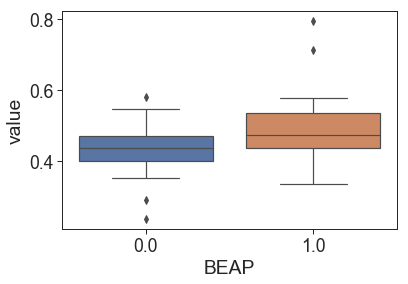

In [90]:
sns.boxplot(x="BEAP", y="value", data=pd.DataFrame([beap_features.loc[:, 'ICVF_superior_corona_radiata_right'], beap]).T.melt(id_vars=['BEAP']))

In [121]:
jhu_annotations = pd.read_csv('../../data/Atlas/jhu_atlas_neonate/label_JHU-neonate-SS_seg.csv', header=None)
jhu_annotations_dict = {}
jhu_annotations_dict2 = {}
template_b0 = ants.image_read('results/processed/sub-143_T1w_noise_corrected_reoriented_enh_b0.nii.gz')
template_mask = template_b0.get_mask()
jhu_atlas = ants.image_read('results/template/JHU_Atlas_JHU_neonate_SS_122parcellation.nii.gz')
jhu_mat = ants.images_to_matrix([jhu_atlas], template_mask)
albert06 = ants.image_read('results/ALBERTs/ALBERT_06-session1/T2/ALBERT_06-session1.nii.gz')
albert06_mask = albert06.get_mask()
jhu_atlas2 = ants.image_read('results/template/ALBERT_06_warp_to_JHU_JHU_neonate_SS_122parcellation.nii.gz')
jhu_mat2 = ants.images_to_matrix([jhu_atlas2], albert06_mask)
for i in range(jhu_annotations.shape[0]):
    jhu_annotations_dict[jhu_annotations.iloc[i, 0]] = '_'.join(jhu_annotations.iloc[i, 1:-1].tolist()).replace(' ', '_')
    jhu_annotations_dict2['_'.join(jhu_annotations.iloc[i, 1:-1].tolist()).replace(' ', '_')] = jhu_annotations.iloc[i, 0]    
native_modalities = ['tissue_label', 'b0', 't1', 
                     'alff', 'falff', 'reho', 
                     'fa', 'md', 
                     'od', 'icvf', 'isovf']
templates = []
for t in native_modalities:
    templates.append(ants.image_read(glob.glob(f'{t}_mean_template.nii.gz')[0]))
    
visualize_data = leave1_ttest.iloc[:5, :]    
all_corrs_colname_roi_num = [jhu_annotations_dict2[i] for i in visualize_data.index.map(lambda x: x.split('_', 1)[1])]
all_corrs_modals = [ i for i in visualize_data.index.map(lambda x: x.split('_', 1)[0])]
visualize_data = visualize_data.fillna(0)
visualize_data

,t,fdr
fALFF_supramarginal_gyrus_left,-4.647598,0.000186
fALFF_cingular_gyrus_right,-4.547946,0.000186
fALFF_anterior_corona_radiata_right,-4.404122,0.000219
fALFF_lyngual_gyrus_right,-3.929549,0.000564
fALFF_precuneus_right,-3.978143,0.000564


In [122]:
all_corrs_modals

['fALFF', 'fALFF', 'fALFF', 'fALFF', 'fALFF']

In [123]:
modal_activate = {}
modal_outcome = "BEAP"
modal_activate["BEAP"] = {}
for col, modal, roi in zip(visualize_data.index, all_corrs_modals, all_corrs_colname_roi_num):
    modal_activate["BEAP"][modal] = modal_activate["BEAP"].get(modal, 0) + (jhu_mat == roi)*visualize_data.loc[col, 't']
    
for modal in np.unique(all_corrs_modals):
    if (modal_activate[modal_outcome][modal] == 0).all(): print(modal_activate[modal_outcome][modal])
    modal_activate[modal_outcome][modal] = ants.matrix_to_images(modal_activate[modal_outcome][modal], 
                                                                 template_mask)[0].crop_image(template_mask)

In [125]:
plotting.view_img(ants.to_nibabel(modal_activate[modal_outcome][modal]), 
                  bg_img=ants.to_nibabel(templates[1].crop_image(template_mask)))

## Leave 10 out cross validation

In [172]:
all_perfs = []
cv = RepeatedStratifiedKFold(5, 10, random_state=seed)
predictions = []
print('running cross validation')
clf = xgb.XGBClassifier(learning_rate=0.1, #reg_lambda=1e-8, reg_alpha=1e-8,
                  n_estimators=10,
                  max_depth=10,
                  min_child_weight = 1,
                  gamma=0.,
                  subsample=0.9,
                  colsample_btree=0.9,
                  objective='binary:logistic',
                  random_state=seed)
clf = Pipeline([
    ("std", StandardScaler()),
    ("fs",  SelectP(f_classif, alpha=0.05)),
   #("fs",  SelectFdr(f_classif, alpha=0.05)),
    #('smote', SMOTE(random_state=seed)),    
#        ("fs",  SelectKBest(f_classif, k=122)),
    ("clf", clf)
])
params = {
    'clf__n_estimators': [2, 8, 10],
    'clf__max_depth': [2, 8, 10],
    'clf__reg_lambda': scipy.stats.distributions.uniform(1000, 100000)    
}

clf1 = Pipeline([
    ("std", StandardScaler()),
    ("fs",  SelectP(f_classif, alpha=0.05)),
  #  ("fs",  SelectFdr(f_classif, alpha=0.05)),
    #('smote', SMOTE(random_state=seed)),
#        ("fs",  SelectKBest(f_classif, k=122)),
    ("clf", SVC(C=1e8, kernel='linear', probability=True, max_iter=500000, random_state=seed))
])    
params1 = {
#    'clf__C': [100, 200, 300, 400, 500]
    'clf__C': scipy.stats.distributions.uniform(1000, 100000)        
}

clf2 = Pipeline([
    ("std", StandardScaler()),
    ("fs",  SelectP(f_classif, alpha=0.05)),
#    ("fs",  SelectFdr(f_classif, alpha=0.05)),        
#        ("fs",  SelectKBest(f_classif, k=122)), 
    #('smote', SMOTE(random_state=seed)),    
    ("clf", LogisticRegression(penalty='l1', solver='liblinear', C=100000000,
                               max_iter=5000, random_state=seed))
])    
params2 = {
#    'clf__C': [100, 200, 300, 400, 500]
    'clf__C': scipy.stats.distributions.uniform(1000, 100000)
} 
scoring = {'AUC': 'roc_auc', 'Accuracy': 'accuracy', 'PRAUC': make_scorer(average_precision_score, greater_is_better=True),
           "specificity": spec_score, "FPR": fpr_score,
           'f1': 'f1', 'recall': 'recall', 'precision': 'precision'}

for m, clf, param in zip(['xgboost', 'svm', 'logit'], [clf, clf1, clf2], [params, params1, params2]):    
#     model = GridSearchCV(clf,  param_grid=param, scoring=scoring, 
#                          refit='f1', cv=cv, n_jobs=30, return_train_score=True)    
    model = RandomizedSearchCV(clf, param_distributions=param, n_iter=30, cv=cv, refit='f1', n_jobs=30,
                               scoring=scoring,
                               return_train_score=True)
    model.fit(beap_features.loc[:, leave1_ttest.index[:10]], beap, groups=beap)
    print(model.best_params_)
#    print(model.cv_results_)
#     print(model.cv_results_['mean_test_AUC'][model.best_index_])
#     print(model.cv_results_)    
    model_perf = pd.DataFrame(model.cv_results_)
    model_perf = model_perf.loc[:, model_perf.columns.str.contains('split') & model_perf.columns.str.contains('test')]
    all_perfs.append([m, seed,
                      model.cv_results_['mean_test_AUC'][model.best_index_],
                      model.cv_results_['std_test_AUC'][model.best_index_],
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('AUC')].min(),
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('AUC')].max(),

                      model.cv_results_['mean_test_PRAUC'][model.best_index_],
                      model.cv_results_['std_test_PRAUC'][model.best_index_],
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_PRAUC')].min(),
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_PRAUC')].max(),

                      model.cv_results_['mean_test_f1'][model.best_index_],
                      model.cv_results_['std_test_f1'][model.best_index_],
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_f1')].min(),
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_f1')].max(),

                      model.cv_results_['mean_test_recall'][model.best_index_],
                      model.cv_results_['std_test_recall'][model.best_index_],
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_recall')].min(),
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_recall')].max(),  

                      model.cv_results_['mean_test_precision'][model.best_index_],
                      model.cv_results_['std_test_precision'][model.best_index_],
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_precision')].min(),
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_precision')].max(),

                      model.cv_results_['mean_test_Accuracy'][model.best_index_],
                      model.cv_results_['std_test_Accuracy'][model.best_index_],
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_Accuracy')].min(),
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_Accuracy')].max(),

                      model.cv_results_['mean_test_specificity'][model.best_index_],
                      model.cv_results_['std_test_specificity'][model.best_index_],
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_specificity')].min(),
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_specificity')].max(),

                      model.cv_results_['mean_test_FPR'][model.best_index_],
                      model.cv_results_['std_test_FPR'][model.best_index_],
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_FPR')].min(),
                      model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_FPR')].max()])      

running cross validation
{'clf__max_depth': 2, 'clf__n_estimators': 2, 'clf__reg_lambda': 14354.234571904723}


/home/qinqian/.local/lib/python3.6/site-packages/sklearn/svm/base.py:227: ConvergenceWarning: Solver terminated early (max_iter=500000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  % self.max_iter, ConvergenceWarning)


{'clf__C': 61823.94289180335}
{'clf__C': 80718.19759183611}


In [173]:
cols = ['AUC', 'PRAUC', 'f1', 'recall', 'precision', 'Accuracy', 'specificity', 'FPR']
cols_all = []
for i in cols:
    cols_all.append(i+'_mean')
    cols_all.append(i+'_sd')
    cols_all.append(i+'_min')
    cols_all.append(i+'_max')     
    
perfs = pd.DataFrame(all_perfs)
perfs.columns = ['method', 'seed'] + cols_all
perfs = perfs.T
perfs.to_csv('Figure3_BEAP_tencross_10feature.csv')
perfs

,0,1,2
method,xgboost,svm,logit
seed,9,9,9
AUC_mean,0.680188,0.570931,0.704265
AUC_sd,0.146945,0.261824,0.144252
AUC_min,0.181818,0.0147059,0.181818
AUC_max,1,0.944444,1
PRAUC_mean,0.307059,0.287182,0.329943
PRAUC_sd,0.138341,0.128408,0.152117
PRAUC_min,0.181818,0.172078,0.181818
PRAUC_max,0.607955,0.795455,0.797619


## Selected features for leave one out

In [12]:
results = []
for seed in [9]:
    cv = LeaveOneOut()
    selectp = SelectFdr(f_classif, alpha=0.05)
    #selectp = SelectP(f_classif, alpha=0.01)
    logit = LogisticRegression(penalty='none', #penalty='l1',  solver='liblinear',
                               max_iter=10000,
                               random_state=seed)
    logit = Pipeline([
        ("std", StandardScaler()),
        ("fs", selectp),
        ("clf", logit)
    ])
    all_outcome_features = []
    clf = logit
    for outcome, name in zip([beap], ['BEAP']):
        predictions = []       
        n = 0
        for train_index, test_index in cv.split(beap_features):    
            fss = ['fALFF_precuneus_right', 'ReHo_cingulum_cingular_part_left', 'ICVF_superior_corona_radiata_right', 'bw']
            X_train_res = beap_features.iloc[train_index, :].loc[:, fss]
            Y_train_res = outcome.iloc[train_index]        
            clf.fit(X_train_res, Y_train_res)        

            pred = clf.predict_proba(beap_features.iloc[test_index, :].loc[:, fss])   
            predictions.append([pred.argmax(1)[0],
                                outcome.iloc[test_index].values[0]])
            inc_features = clf.named_steps['fs'].transform(beap_features.iloc[train_index, :].loc[:, fss].columns.values.reshape(1, -1))[0]   
            if n == 0:
                all_features = set(list(inc_features))
            else:
#                all_features = all_features.intersection(inc_features)
                all_features = all_features.union(inc_features) ## use this one
            n += 1        
        print(name)
        print('-'*10)
        perf = pd.DataFrame(predictions)
        all_outcome_features.append([name, ';'.join(list(all_features)), 
                                     confusion_matrix(perf.iloc[:, 1], perf.iloc[:, 0]).ravel()])
        
    perfs = pd.DataFrame(all_outcome_features)
    results.append([seed, 'model', 'sensitivity', 'specificity', 'positive predictive value', 'negative predictive value'])
    for o, stat in zip(perfs.iloc[:, 0], perfs.iloc[:, 2]):
        tn, fp, fn, tp = stat
        results.append([o, 'logistic regression', tp/(fn+tp), tn/(tn+fp), tp/(tp+fp), tn/(tn+fn)])

BEAP
----------


In [13]:
pd.DataFrame(results)

,0,1,2,3,4,5
0,9,model,sensitivity,specificity,positive predictive value,negative predictive value
1,BEAP,logistic regression,0.4,0.966292,0.727273,0.877551
